In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.font_manager import FontProperties, fontManager
from matplotlib.ticker import FuncFormatter

font_path = '../Helvetica.ttf' 
fontManager.addfont(font_path)
prop = FontProperties(fname=font_path)
font_name = prop.get_name()
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = [font_name] 
print("Current font settings:", plt.rcParams['font.sans-serif'])

Current font settings: ['Helvetica']


## Check ref_target_seqs.fasta 
* based on MEME Suite alphabet standard https://meme-suite.org/meme/doc/alphabets.html

In [ ]:
def check_protein_standard_alphabet(file_path):
    standard_alphabet = set("ACDEFGHIKLMNPQRSTVWYBXZJ*.")  
    with open(file_path, 'r') as file:
        for line in file:
            if line.startswith('>'): 
                continue
            sequence = line.strip()
            if not set(sequence).issubset(standard_alphabet):
                invalid_chars = set(sequence) - standard_alphabet  
                print(line, invalid_chars)
    return 


check_protein_standard_alphabet('../UniPert/data/ref_target_seq.fasta')


RGPSSGGUG
 {'U'}
KCGLTKQLLDDTIGIHPTCGEVFTTLEITKSSGLDITQKGCUG
 {'U'}
MWRSLGLALALCLLPSGGTESQDQSSLCKQPPAWSIRDQDPMLNSNGSVTVVALLQASUY
 {'U'}
PGLHHHHKHKGQHRQGHPENRDMPASEDLQDLQKKLCRKRCINQLLCKLPTDSELAPRSU
 {'U'}
CCHCRHLIFEKTGSAITUQCKENLPSLCSUQGLRAEENITESCQURLPPAAUQISQQLIP
 {'U'}
TEASASURUKNQAKKUEUPSN
 {'U'}
QKLDFFKQAHEGGPAPNSEVVLPDGFQSQHILDYAQGNRPLVLNFGSCTUPPFMARMSAF
 {'U'}
MCAARLAAAAAAAQSVYAFSARPLAGGEPVSLGSLRGKVLLIENVASLUGTTVRDYTQMN
 {'U'}
GFVCIVTNVASQUGKTEVNYTQLVDLHARYAECGLRILAFPCNQFGKQEPGSNEEIKEFA
 {'U'}
MRLLLLLLVAASAMVRSEASANLGGVPSKRLKMQYATGPLLKFQICVSUGYRRVFEEYMR
 {'U'}
QLPWLNUSSCLSLLRSTPAASCEEEELPPDPSEETLTIEARFQPLLPETMTKSKDGFLGV
 {'U'}
AMYPFKKVSYLPFTEAFDRAKAENKLVHSILLWGALDDQSCUGSGRTLRETVLESSPILT
 {'U'}
GKHVLFVNVAAYUGLAAQYPELNALQEELKNFGVIVLAFPCNQFGKQEPGTNSEILLGLK
 {'U'}
IKCGASYAQVMRTVGIHPTCSEEVVKLRISKRSGLDPTVTGCUG
 {'U'}
MAPRGRKRKAEAAVVAVAEKREKLANGGEGMEEATVVIEHCTSURVYGRNAAALSQALRL
 {'U'}
MALAVRVVYCGAUGYKSKYLQLKKKLEDEFPGRLDICGEGTPQATGFFEVMVAGKLIHSK
 {'U'}
ERPLVVNFGSATUPPFTSQLPAFRKLVEEFSSVAD

In [ ]:
def replace_u_with_x(file_path, output_path):
    with open(file_path, 'r') as infile, open(output_path, 'w') as outfile:
        for line in infile:
            if line.startswith('>'):  
                modified_line = line.replace('->', '-)') 
                outfile.write(modified_line)
            else:
                modified_line = line.replace('U', 'X') 
                outfile.write(modified_line)

replace_u_with_x('../UniPert/data/ref_target_seq.fasta', '../UniPert/data/ref_target_seqs_U2X.fasta')

## Download UniPert tsne features

In [ ]:
import pandas as pd
import numpy as np

pc_df_with_tsne = pd.read_csv('../UniPert/data/ref_proteins_with_tsne_fea.csv')


In [7]:
pc_df_with_tsne

,UniProt Accessions,t-SNE_1,t-SNE_2
0,P04217,-29.338383,-77.085495
1,Q9NQ94,41.176685,51.477955
2,P01023,-16.478796,-55.095820
3,A8K2U0,-16.476618,-55.095650
4,U3KPV4,-16.545820,-36.608704
...,...,...,...
19182,Q6WRX3,4.960499,-81.414320
19183,Q9C0D3,4.958026,-81.417000
19184,Q15942,-62.839474,30.582240
19185,O43149,32.678772,-7.176747


## Plot AME motif results

* analysis tool: https://meme-suite.org/meme/tools/ame
* input file: ref_target_seqs_U2X.fasta

### ame_prosite results

In [ ]:
e_results = pd.read_csv('../UniPert/results/meme_results/ame_prosite2021.tsv', sep='\t')
motifs = e_results[['motif_alt_ID', 'consensus', 'E-value']]
motifs

,motif_alt_ID,consensus,E-value
0,G_PROTEIN_RECEP_F1_1,XSXXXLXXLSXERSXXL,1.960000e-136
1,PROTEIN_KINASE_ST,LXYXDLKXXNLLL,7.630000e-96
2,HOMEOBOX_1,LLXXLXLXXXXLSLWVXAXXXXXA,1.900000e-53
3,PROTEIN_KINASE_TYR,LXYXDLSXXNLLL,1.050000e-47
4,ZF_RING_1,CXHXLCXXCL,1.270000e-47
...,...,...,...
97,TCP1_2,LSKBAAALLXXLXLXSA,9.500000e+00
98,NA_SOLUT_SYMP_1,SXXLXXXXXXXXXXXXXLSXXGGLXS,9.500000e+00
99,NaN,NaN,NaN
100,NaN,NaN,NaN


In [ ]:
meme_results_df = pd.read_csv('../UniPert/results/meme_results/ame_prosite_sequences.tsv', sep='\t')

motif_data = meme_results_df[['motif_ALT_ID', 'seq_ID']]
motif_data['UniProt Accessions'] = motif_data['seq_ID'].str.split('|').str[1]  # 提取UniProt accession
motif_data = motif_data.drop(columns=['seq_ID'])
motif_data = motifs.merge(motif_data, left_on='motif_alt_ID', right_on='motif_ALT_ID', how='left')
motif_data

/tmp/ipykernel_2058879/3649977293.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  motif_data['UniProt Accessions'] = motif_data['seq_ID'].str.split('|').str[1]  # 提取UniProt accession


,motif_alt_ID,consensus,E-value,motif_ALT_ID,UniProt Accessions
0,G_PROTEIN_RECEP_F1_1,XSXXXLXXLSXERSXXL,1.960000e-136,G_PROTEIN_RECEP_F1_1,Q15617
1,G_PROTEIN_RECEP_F1_1,XSXXXLXXLSXERSXXL,1.960000e-136,G_PROTEIN_RECEP_F1_1,Q8NGT7
2,G_PROTEIN_RECEP_F1_1,XSXXXLXXLSXERSXXL,1.960000e-136,G_PROTEIN_RECEP_F1_1,P48039
3,G_PROTEIN_RECEP_F1_1,XSXXXLXXLSXERSXXL,1.960000e-136,G_PROTEIN_RECEP_F1_1,Q96R48
4,G_PROTEIN_RECEP_F1_1,XSXXXLXXLSXERSXXL,1.960000e-136,G_PROTEIN_RECEP_F1_1,Q8NGG7
...,...,...,...,...,...
16509,NaN,NaN,NaN,NaN,NaN
16510,NaN,NaN,NaN,NaN,NaN
16511,NaN,NaN,NaN,NaN,NaN
16512,NaN,NaN,NaN,NaN,NaN


In [11]:
pc_df_with_motifs = pc_df_with_tsne.merge(motif_data, left_on='UniProt Accessions', right_on='UniProt Accessions', how='left')
pc_df_with_motifs = pc_df_with_motifs.sort_values(by='E-value')  


In [12]:
pc_df_with_motifs

,UniProt Accessions,t-SNE_1,t-SNE_2,motif_alt_ID,consensus,E-value,motif_ALT_ID
14658,P04001,80.875320,-23.024166,G_PROTEIN_RECEP_F1_1,XSXXXLXXLSXERSXXL,1.960000e-136,G_PROTEIN_RECEP_F1_1
15117,Q8NGX8,90.528030,19.291777,G_PROTEIN_RECEP_F1_1,XSXXXLXXLSXERSXXL,1.960000e-136,G_PROTEIN_RECEP_F1_1
15116,Q8NH79,87.685020,-3.449350,G_PROTEIN_RECEP_F1_1,XSXXXLXXLSXERSXXL,1.960000e-136,G_PROTEIN_RECEP_F1_1
15113,Q8N148,88.645065,-10.137287,G_PROTEIN_RECEP_F1_1,XSXXXLXXLSXERSXXL,1.960000e-136,G_PROTEIN_RECEP_F1_1
23759,Q9UKP6,85.354060,-29.778618,G_PROTEIN_RECEP_F1_1,XSXXXLXXLSXERSXXL,1.960000e-136,G_PROTEIN_RECEP_F1_1
...,...,...,...,...,...,...,...
25263,Q6WRX3,4.960499,-81.414320,NaN,NaN,NaN,NaN
25264,Q9C0D3,4.958026,-81.417000,NaN,NaN,NaN,NaN
25265,Q15942,-62.839474,30.582240,NaN,NaN,NaN,NaN
25266,O43149,32.678772,-7.176747,NaN,NaN,NaN,NaN


In [13]:
pc_df_with_motifs.loc[:,['motif_ALT_ID']].value_counts()

motif_ALT_ID        
ASN_GLYCOSYLATION       4321
MYRISTYL                3123
ATP_GTP_A               1923
LEUCINE_ZIPPER           742
G_PROTEIN_RECEP_F1_1     522
                        ... 
MCM_1                     12
GDA1_CD39_NTPASE          12
ALDOKETO_REDUCTASE_1      11
TCP1_2                    10
NA_SOLUT_SYMP_1           10
Name: count, Length: 99, dtype: int64

In [14]:
pc_df = pc_df_with_motifs

In [28]:
unique_motifs = list(pc_df_with_motifs.loc[:,['motif_alt_ID', 'E-value']].drop_duplicates()['motif_alt_ID'].values)
num_motifs = 8

520 23459 25268
G_PROTEIN_RECEP_F1_1
XSXXXLXXLSXERSXXL


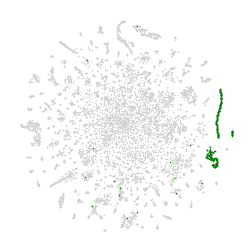

415 23564 25268
PROTEIN_KINASE_ST
LXYXDLKXXNLLL


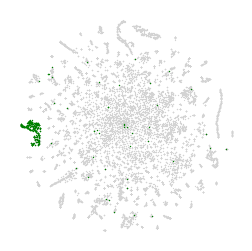

192 23787 25268
HOMEOBOX_1
LLXXLXLXXXXLSLWVXAXXXXXA


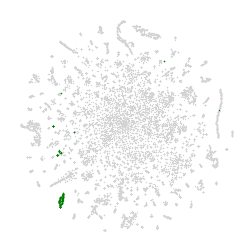

343 23636 25268
PROTEIN_KINASE_TYR
LXYXDLSXXNLLL


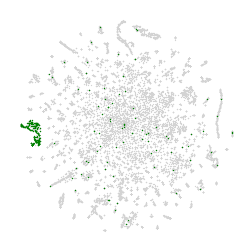

205 23774 25268
ZF_RING_1
CXHXLCXXCL


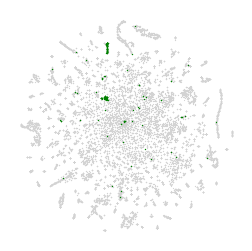

1823 22156 25268
ATP_GTP_A
AXXXXGKS


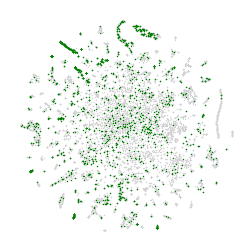

141 23838 25268
SIGMA54_INTERACT_1
LLLXGESGSGKXXL


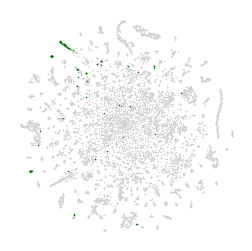

197 23782 25268
WD_REPEATS_1
LXLLXXBXXLXLWEX


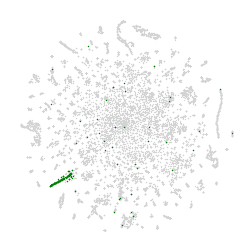

In [31]:
import numpy as np
import matplotlib.colors as mcolors

for i, motif in enumerate(unique_motifs[:8]):
    motif_data = pc_df[pc_df['motif_ALT_ID'] == motif]
    other_data = pc_df[pc_df['motif_ALT_ID'] != motif] 

    print(len(motif_data.drop_duplicates()), len(other_data.drop_duplicates()), len(motif_data)+len(other_data))

    seq = str(motif_data['consensus'].values[0])
    if len(seq) <= 5: 
        continue
    
    plt.figure(figsize=(3, 3))  
    
    plt.scatter(other_data['t-SNE_1'], 
                other_data['t-SNE_2'], 
                alpha=1, 
                s=0.75, 
                c='lightgray', 
                linewidths=0.0)
    
    plt.scatter(motif_data['t-SNE_1'], 
                motif_data['t-SNE_2'], 
                alpha=1, 
                s=1, 
                c='g',  
                linewidths=0.0)

    print(f'{motif}\n{seq}')
    plt.xticks([])
    plt.yticks([])
    
    ax = plt.gca()
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_visible(False)

    plt.show()

### ame_elm

In [32]:
e_results = pd.read_csv('../results/meme_results/ame_elm.tsv', sep='\t')
motifs = e_results[['motif_alt_ID', 'consensus', 'E-value']]
motifs

,motif_alt_ID,consensus,E-value
0,LIG_APCC_Cbox_2,DRFLAXX,1.800000e-80
1,MOD_LATS_1,HXKXXSX,9.070000e-79
2,LIG_WW_2,PPLP,2.180000e-48
3,LIG_MYND_1,PXLXP,4.890000e-34
4,DOC_USP7_UBL2_3,KXXXK,6.420000e-30
5,LIG_SH3_PxRPPK_7,LPELPPKX,1.230000e-29
6,DEG_Kelch_KLHL12_1,APGAPP,9.980000e-25
7,MOD_N-GLC_1,XNXSXX,1.170000e-24
8,LIG_SH3_CIN85_PxpxPR_1,PXAXPR,2.630000e-24
9,LIG_PTAP_UEV_1,XPSAPX,6.880000e-24


In [33]:
meme_results_df = pd.read_csv('../results/meme_results/ame_elm_sequences.tsv', sep='\t')

motif_data = meme_results_df[['motif_ALT_ID', 'seq_ID']]
motif_data['UniProt Accessions'] = motif_data['seq_ID'].str.split('|').str[1]  
motif_data = motif_data.drop(columns=['seq_ID'])
motif_data = motifs.merge(motif_data, left_on='motif_alt_ID', right_on='motif_ALT_ID', how='left')
motif_data

/tmp/ipykernel_2058879/120923824.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  motif_data['UniProt Accessions'] = motif_data['seq_ID'].str.split('|').str[1]


,motif_alt_ID,consensus,E-value,motif_ALT_ID,UniProt Accessions
0,LIG_APCC_Cbox_2,DRFLAXX,1.800000e-80,LIG_APCC_Cbox_2,Q5JTB6
1,LIG_APCC_Cbox_2,DRFLAXX,1.800000e-80,LIG_APCC_Cbox_2,Q8NGP6
2,LIG_APCC_Cbox_2,DRFLAXX,1.800000e-80,LIG_APCC_Cbox_2,Q96R48
3,LIG_APCC_Cbox_2,DRFLAXX,1.800000e-80,LIG_APCC_Cbox_2,Q15617
4,LIG_APCC_Cbox_2,DRFLAXX,1.800000e-80,LIG_APCC_Cbox_2,Q8NGB8
...,...,...,...,...,...
155122,NaN,NaN,NaN,NaN,NaN
155123,NaN,NaN,NaN,NaN,NaN
155124,NaN,NaN,NaN,NaN,NaN
155125,NaN,NaN,NaN,NaN,NaN


In [34]:
pc_df_with_motifs = pc_df_with_tsne.merge(motif_data, left_on='UniProt Accessions', right_on='UniProt Accessions', how='left')
pc_df_with_motifs = pc_df_with_motifs.sort_values(by='E-value') 


In [35]:
pc_df_with_motifs

,UniProt Accessions,t-SNE_1,t-SNE_2,motif_alt_ID,consensus,E-value,motif_ALT_ID
91890,Q9H346,101.703250,-4.145825,LIG_APCC_Cbox_2,DRFLAXX,1.800000e-80,LIG_APCC_Cbox_2
42168,Q9P2D6,23.360186,-3.658672,LIG_APCC_Cbox_2,DRFLAXX,1.800000e-80,LIG_APCC_Cbox_2
89359,Q8NGV7,90.458770,18.985930,LIG_APCC_Cbox_2,DRFLAXX,1.800000e-80,LIG_APCC_Cbox_2
89373,Q8NGV6,87.034640,3.776916,LIG_APCC_Cbox_2,DRFLAXX,1.800000e-80,LIG_APCC_Cbox_2
87191,P47887,90.183400,17.869480,LIG_APCC_Cbox_2,DRFLAXX,1.800000e-80,LIG_APCC_Cbox_2
...,...,...,...,...,...,...,...
115481,Q99470,10.715456,-23.499825,NaN,NaN,NaN,NaN
124416,Q00796,-80.208350,30.659883,NaN,NaN,NaN,NaN
126684,Q8NEQ6,57.653910,-2.936383,NaN,NaN,NaN,NaN
132880,O15482,31.942926,19.429373,NaN,NaN,NaN,NaN


In [36]:
pc_df_with_motifs.loc[:,['motif_ALT_ID']].value_counts()

motif_ALT_ID          
LIG_SH3_3                 12274
MOD_CK1_1                 11161
LIG_SH2_STAP1             11034
DOC_USP7_UBL2_3           10634
LIG_NRBOX                  8576
CLV_PCSK_FUR_1             8548
CLV_PCSK_PC7_1             7978
LIG_SH3_1                  7371
LIG_MYND_1                 7338
LIG_SH3_2                  7288
MOD_N-GLC_1                6965
CLV_PCSK_SKI1_1            6712
LIG_Pex14_2                5910
LIG_GBD_Chelix_1           5261
TRG_NESrev_CRM1_2          3631
CLV_Separin_Metazoa        3279
LIG_Pex3_1                 2978
MOD_DYRK1A_RPxSP_1         2415
LIG_WW_2                   2306
DEG_Kelch_KLHL12_1         2152
LIG_SH2_CRK                2001
TRG_DiLeu_LyEn_5           1768
LIG_Pex14_3                1756
LIG_AP2alpha_1             1567
LIG_SPRY_1                 1503
LIG_FAT_LD_1               1401
LIG_SH3_CIN85_PxpxPR_1     1360
LIG_RPA_C_Plants           1141
LIG_PTAP_UEV_1             1113
LIG_APCC_Cbox_1             961
MOD_PRMT_GGRGG_1 

In [40]:
pc_df = pc_df_with_motifs

In [39]:
unique_motifs = pc_df_with_motifs.loc[:,['motif_alt_ID', 'E-value']].drop_duplicates()['motif_alt_ID'].values

405 128208 155009
LIG_APCC_Cbox_2
DRFLAXX


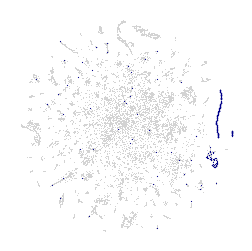

424 128189 155009
MOD_LATS_1
HXKXXSX


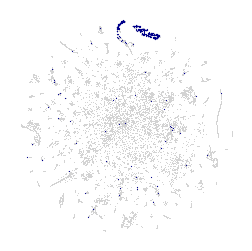

In [43]:
import numpy as np
import matplotlib.colors as mcolors

for i, motif in enumerate(unique_motifs[:2]):
    motif_data = pc_df[pc_df['motif_ALT_ID'] == motif]
    other_data = pc_df[pc_df['motif_ALT_ID'] != motif]  

    print(len(motif_data.drop_duplicates()), len(other_data.drop_duplicates()), len(motif_data)+len(other_data))

    seq = str(motif_data['consensus'].values[0])
    
    plt.figure(figsize=(3, 3))  

    plt.scatter(other_data['t-SNE_1'], 
                other_data['t-SNE_2'], 
                alpha=1, 
                s=0.5, 
                c='lightgray', 
                linewidths=0.0)
    
    plt.scatter(motif_data['t-SNE_1'], 
                motif_data['t-SNE_2'], 
                alpha=1, 
                s=0.75, 
                c='darkblue', 
                linewidths=0.0)

    print(f'{motif}\n{seq}')
    plt.xticks([])
    plt.yticks([])
    
    ax = plt.gca()
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_visible(False)

    plt.show()